# TSA Complaints: Data Preparation for a Tableau Dashboard

**Question:** where and why are travelers complaining to the TSA, so airport operations managers can decide where to act?

**Audience and medium:** airport operations managers, through an interactive Tableau dashboard (`DSC640_Week9and10.twbx`) with a map of complaints by airport, yearly trends, top categories and subcategories, and variability by month. This notebook is the ETL step that builds the single data file the dashboard uses.

**Data:** TSA complaint counts by airport, month, category and subcategory, January 2015 to January 2024, from seven report editions, plus an airport code lookup table with names and coordinates.

**Approach:** drop rows with no airport, confirm the report editions do not overlap, combine subcategories that share a standardized name, add airport names and locations, and save one tidy file for Tableau.

**Key results:**
- The output file holds 583,206 complaints at 443 airports. Another 437,786 complaints (43% of the total) have no airport and could not be mapped.
- The top airports by complaints are Los Angeles (24,794), JFK (24,677), Newark (24,405), Atlanta (23,591) and Orlando (22,308).
- The Expedited Passenger Screening Program is the largest category (37.1% of complaints), and it explains the jump from about 48,000 complaints in 2021 to 120,000 to 128,000 in 2022 and 2023.

**Tools:** Python (pandas, matplotlib) for ETL; Tableau for the dashboard

**Context:** master's coursework (DSC640, Weeks 9 and 10), cleaned up for this portfolio.

## 1. Load the data

In [1]:
# import the required libraries
import warnings
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=FutureWarning)

In [2]:
# TSA complaint counts by airport, category and subcategory, plus an airport code lookup table
df_subcategory = pd.read_csv('complaints-by-subcategory.csv')
df_iata_icao = pd.read_csv('iata-icao.csv')
print(f'Subcategory rows: {len(df_subcategory):,}   Report editions: {df_subcategory["pdf_report_date"].nunique()}')
df_subcategory.head()

Subcategory rows: 504,512   Report editions: 7


,pdf_report_date,airport,category,subcategory,year_month,count,clean_cat,clean_subcat,clean_cat_status,clean_subcat_status,is_category_prefix_removed
0,2019-02,ABE,Hazardous Materials Safety,General,2015-01,0,Hazardous Materials Safety,General,original,original,False
1,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-01,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False
2,2019-02,ABE,Hazardous Materials Safety,General,2015-02,0,Hazardous Materials Safety,General,original,original,False
3,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-02,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False
4,2019-02,ABE,Hazardous Materials Safety,General,2015-03,0,Hazardous Materials Safety,General,original,original,False


## 2. Clean
- Rows with no airport are dropped, since they cannot be placed on a map (so totals below slightly understate all complaints).
- The subcategory file is used because it already has standardized category and subcategory names (`clean_cat`, `clean_subcat`); the category and airport files repeat the same counts at a higher level.
- Each airport and month appears in only one report edition, so combining editions does not double count.

In [3]:
no_airport = df_subcategory['airport'].isna()
print(f"Rows without an airport: {no_airport.sum():,} ({df_subcategory.loc[no_airport, 'count'].sum():,} complaints)")
df_sub = df_subcategory[~no_airport].rename(columns={'airport': 'iata'})

editions_per_month = df_sub.groupby(['iata', 'year_month', 'clean_cat', 'clean_subcat'])['pdf_report_date'].nunique()
print('Airport-month-category combinations found in more than one report edition:', (editions_per_month > 1).sum())

# several original subcategories map to the same standardized name, so add them together
complaints_data = (df_sub.assign(year_month=pd.to_datetime(df_sub['year_month'], format='%Y-%m'))
                   .groupby(['iata', 'year_month', 'clean_cat', 'clean_subcat'])['count'].sum().reset_index())
print(f'Rows after combining: {len(complaints_data):,}   Complaints: {complaints_data["count"].sum():,}')

Rows without an airport: 13,464 (437,786 complaints)


Airport-month-category combinations found in more than one report edition: 0


Rows after combining: 481,689   Complaints: 583,495


## 3. Add airport names and locations

In [4]:
airports = (df_iata_icao[['iata', 'airport', 'latitude', 'longitude', 'country_code', 'region_name']]
            .rename(columns={'airport': 'airport_name'}).assign(iata=lambda d: d['iata'].str.upper()))
merged = complaints_data.merge(airports, on='iata', how='left')
unmatched = merged['country_code'].isna()
print(f"Rows with no matching airport code: {unmatched.sum():,} ({merged.loc[unmatched, 'count'].sum():,} complaints, "
      f"codes: {sorted(merged.loc[unmatched, 'iata'].unique())})")
merged = merged[~unmatched]

merged.to_csv('complaints_data_For_Visuals.csv', index=False)
print(f'Saved complaints_data_For_Visuals.csv: {len(merged):,} rows, {merged["count"].sum():,} complaints, '
      f'{merged["iata"].nunique()} airports, {merged["year_month"].min():%b %Y} to {merged["year_month"].max():%b %Y}')

Rows with no matching airport code: 1,306 (289 complaints, codes: ['CEF', 'JQF', 'JRB', 'NYL', 'UNV'])


Saved complaints_data_For_Visuals.csv: 480,383 rows, 583,206 complaints, 443 airports, Jan 2015 to Jan 2024


## 4. Quick checks of what the Tableau dashboard shows

In [5]:
yearly = merged.groupby(merged['year_month'].dt.year)['count'].sum()
months = merged.groupby(merged['year_month'].dt.year)['year_month'].nunique()
print('Complaints by year (months of data):')
print(pd.DataFrame({'complaints': yearly, 'months': months}).to_string())

print('\nTop 5 airports:')
print(merged.groupby(['iata', 'airport_name'])['count'].sum().sort_values(ascending=False).head(5).to_string())
cat = merged.groupby('clean_cat')['count'].sum().sort_values(ascending=False)
print('\nTop 5 categories (share of all complaints):')
print((cat.head(5) / cat.sum() * 100).round(1).to_string())
print('\nTop 5 subcategories:')
print(merged.groupby('clean_subcat')['count'].sum().sort_values(ascending=False).head(5).to_string())

Complaints by year (months of data):
            complaints  months
year_month                    
2015             44507      12
2016             57179      12
2017             53724      12
2018             52544      12
2019             49420      12
2020             20836      12
2021             47857      12
2022            120524      12
2023            128315      12
2024              8300       1

Top 5 airports:
iata  airport_name                                    
LAX   Los Angeles International Airport                   24794
JFK   John F. Kennedy International Airport               24677
EWR   Newark Liberty International Airport                24405
ATL   Hartsfield-Jackson Atlanta International Airport    23591
MCO   Orlando International Airport                       22308

Top 5 categories (share of all complaints):
clean_cat
Expedited Passenger Screening Program    37.1
Mishandling of Passenger Property        19.4
Customer Service                         13.6
Screen

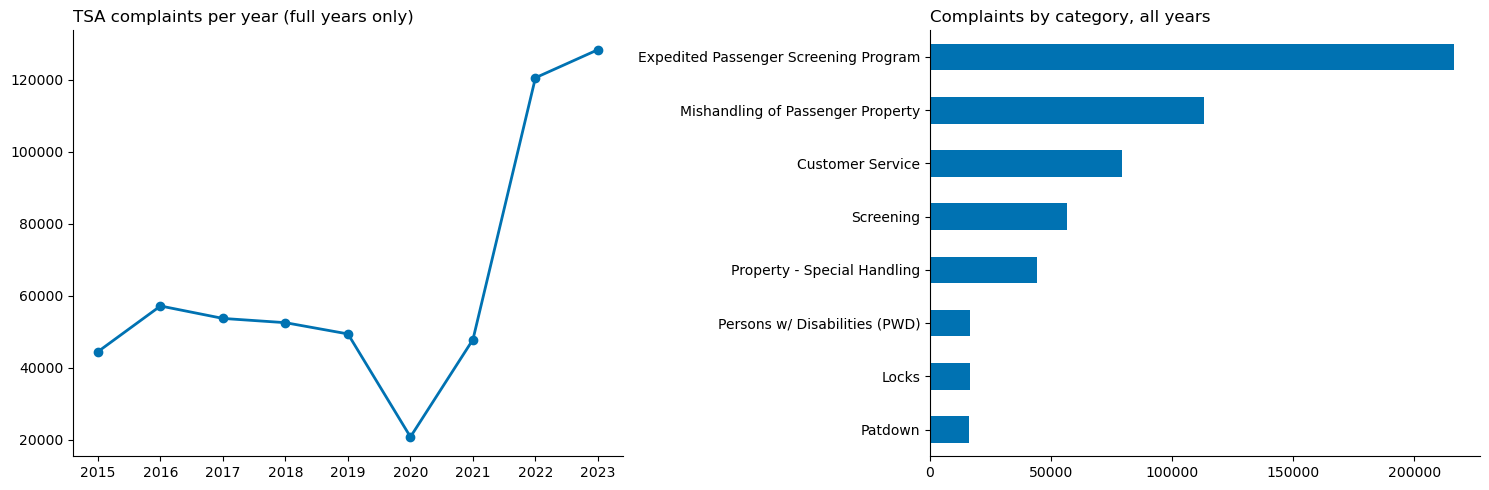

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
full_years = yearly[months == 12]
axes[0].plot(full_years.index, full_years.values, marker='o', color='#0072B2', lw=2)
axes[0].set_title('TSA complaints per year (full years only)', loc='left'); axes[0].set_xlabel('')
axes[0].spines[['top', 'right']].set_visible(False)
cat.head(8).sort_values().plot(kind='barh', ax=axes[1], color='#0072B2')
axes[1].set_title('Complaints by category, all years', loc='left'); axes[1].set_ylabel('')
axes[1].spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Findings
- **The jump in complaints comes from one category.** Total complaints rose from 47,857 in 2021 to 120,524 in 2022 and 128,315 in 2023, but almost all of the increase is the Expedited Passenger Screening Program, which had almost no complaints before 2021 (none at all from 2016 to 2019) and then 91,841 in 2022 and 93,841 in 2023. Without that category, complaints fell from 49,420 in 2019 to 20,734 in 2020 and had recovered to 34,474 by 2023, still below pre-pandemic levels. Why this category appears so suddenly (a new program, or a new way of recording complaints) is worth confirming with the TSA.
- **That category also lacks detail.** Every Expedited Passenger Screening Program complaint has a blank subcategory, so the data cannot say what travelers are complaining about. This supports the original recommendation to find out why the program generates so many complaints.
- **Large hubs lead.** Los Angeles, JFK, Newark, Atlanta and Orlando each have 22,000 to 25,000 complaints over the nine years, which mostly reflects passenger volume. Complaints per passenger would be a fairer comparison.
- **Other common issues:** mishandling of passenger property (19.4% of complaints; checked-baggage damage and missing items is the largest subcategory with a description), customer service (13.6%, with TSO interactions the most common subcategory) and screening (9.7%).
- **Limitation:** 43% of complaints (437,786) have no airport and are excluded, so airport totals understate the true volume.

**Cleanup note:** the original notebook had no written findings; this version adds them, plus checks that the report editions do not double count and that the airport lookup matches (5 codes with 289 complaints had no match). The output file used by Tableau is unchanged in content. The original notebook is in `earlier_versions/`.